# Visualize output of inference

In [79]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [80]:
from scipy.optimize import root_scalar
from scipy.interpolate import interp1d

# autocorrelation function
# FIXME
def autocorrelation(signal):
    x = np.array(signal) 

    # Normalized data
    ndata = x - np.mean(x)
    N = len(ndata)

    # Variance
    var = np.var(x)

    acorr = np.correlate(ndata, ndata, 'full')[N-1:N+N//2] 
    return acorr / (N * var)

# root finder
def find_period(autocorr, tol=1e-6, max_iter=1000):

    interp_func = interp1d(np.arange(len(autocorr)), autocorr, kind='linear')
    end = np.where(autocorr < 0)[0][0]

    if interp_func(0) * interp_func(end) >= 0:
        raise ValueError("The function values at the interval endpoints must have opposite signs.")

    result = root_scalar(interp_func, bracket=[0, end], method='bisect', xtol=tol)

    if result.converged:
        return result.root
    else:
        raise Exception("Root finding did not converge.")
    
# compute mean and standard deviation from uncorrelated samples
def mcmc_mean(data) :
    autocorr = autocorrelation(data)
    period = np.round(find_period(autocorr)).astype(int)

    return [data[::-period].mean(), data[::-period].std(ddof=1)]

In [81]:
def visualizer(results, num_adapt_iter = 5000, burn_in = 5000, target = {}) :
    
    df = results[results.index > num_adapt_iter+burn_in]
    cols = df.columns.to_list()
    cols.remove('loglike')
    param_names = [c for c in cols if "__a%" not in c]

    thinning = df.index[1] - df.index[0]
    iterations = thinning * np.arange(len(df))

    fig, axes = plt.subplots(figsize=(11, 3), ncols=2, )
    fig.subplots_adjust(wspace=0.25)
    
    mu, sigma = mcmc_mean(df["loglike"])
    axes[0].axhline(y=mu, color="black", lw=2, ls="-")
    axes[0].axhline(y=mu-sigma, color="black", lw=2, ls="--")
    axes[0].axhline(y=mu+sigma, color="black", lw=2, ls="--")

    axes[0].plot(df.index, df["loglike"], color = "red", lw=0.5)

    axes[0].set_xlabel("N. of iterations")
    axes[0].set_ylabel("Loglikelihood")

    autocorr = autocorrelation( df["loglike"])
    period = np.round(find_period(autocorr)).astype(int)

    axes[1].plot(iterations[:len(autocorr)], autocorr)
    axes[1].axhline(y=0, color="grey", ls = "--")
    axes[1].axvline(x=thinning * period, color="red", ls="--")


    n_rows = max(2, len(param_names))
    fig, axes = plt.subplots(figsize=(11, 3 * n_rows),
                            nrows=n_rows, ncols=2, sharex=False)
    fig.subplots_adjust(wspace=0.25)

    inferred_parameters = {}

    for i, p in enumerate(param_names) :
        mu, sigma = mcmc_mean(df[p])
        axes[i, 0].axhline(y=mu, color="black", lw=2, ls="-")
        axes[i, 0].axhline(y=mu-sigma, color="black", lw=2, ls="--")
        axes[i, 0].axhline(y=mu+sigma, color="black", lw=2, ls="--")

        axes[i, 0].plot(df.index, df[p], label=p, lw=0.5)
        axes[i, 0].set_ylabel(p)

        if p in target :
            axes[i, 0].axhline(y=target[p], color="red", lw=2, ls="--")


        axes[i, 1].plot(df.index, df[f"{p}__a%"], label=p, lw=1, color="grey")
        axes[i, 1].set_ylabel(f"{p}__a%")
        #axes[i, 0].set_yscale("log")
        #xes[i, 1].set_xscale("log")
        axes[i, 1].set_ylim([0, 50])
        axes[i, 1].axhline(y=25, ls="--", lw=1, color='black')

        inferred_parameters[p] = [mu, sigma]

    axes[0, 0].set_title("Parameter")
    axes[0, 1].set_title("Acceptation Rate")
    axes[-1, 0].set_xlabel("N. of iterations")
    axes[-1, 1].set_xlabel("N. of iterations")

    return inferred_parameters

## Results visualization

beta [0.00044 0.00042]


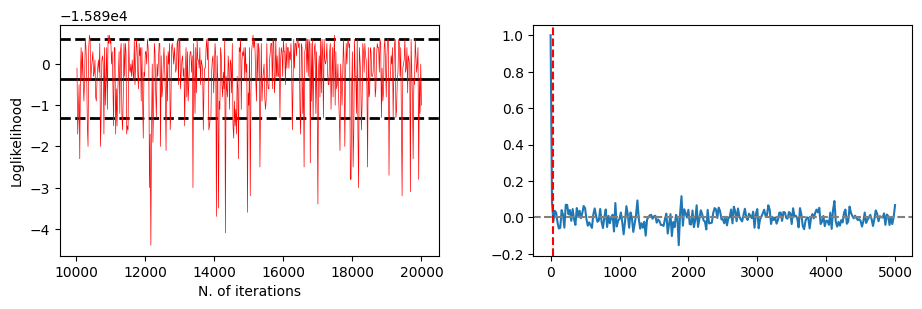

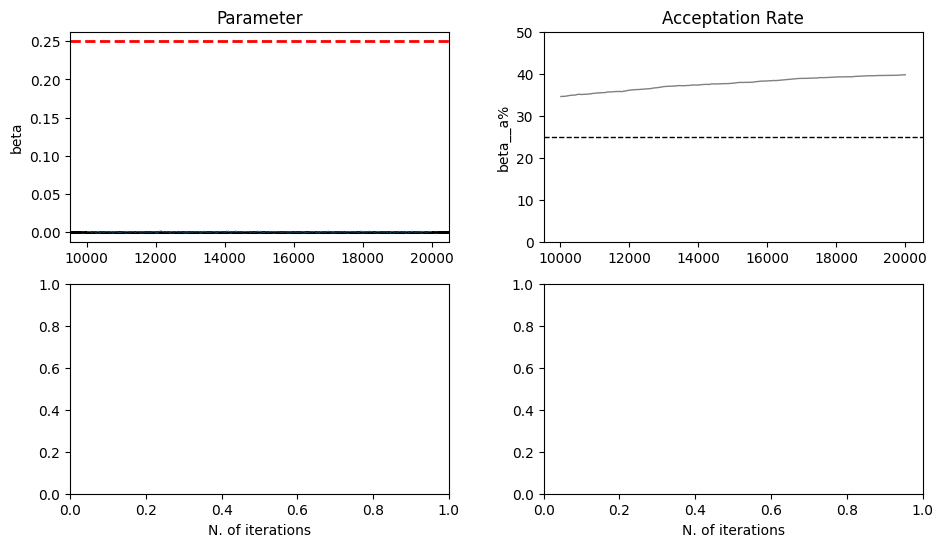

In [82]:
file_name = "../data/parameters.txt"
params = pd.read_csv(file_name, sep=" ", header=None, index_col=0)
target = { p : params.at[p, 1] for p in params.index}

file_name = "../output/validate.txt"
results = pd.read_csv(file_name, sep=" ", index_col="iter")
inferred_parameters = visualizer(results,  num_adapt_iter = 5000, burn_in = 5000, target=target)

for k in inferred_parameters.keys():
    print(k, np.round(inferred_parameters[k], 5))